# Módulo 0. Comprender y preparar los datos de Olist

**Pregunta del proyecto:** al cierre de un día, ¿cuántas órdenes de compra recibirá Olist cada uno de los próximos 28 días?

Desarrollamos el Módulo 0 y el Módulo B del taller. La unidad es una **orden de compra**; la fecha relevante es `order_purchase_timestamp`. Los modelos de clasificación, segmentación y la extensión opcional por categorías o estados quedan fuera del alcance.

Este notebook explica las tablas, comprueba su calidad y construye una serie diaria. El notebook 01 estudia los patrones temporales y el 02 entrena y evalúa los modelos. Ejecuta las celdas en orden; los resultados están guardados para leerlos también en GitHub.

In [4]:
# La ruta funciona tanto al abrir notebooks/ como desde la raíz del proyecto.
from pathlib import Path
import sys, json
ROOT=Path.cwd() if (Path.cwd()/'sql').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.configuracion import INICIO, FIN, SELECCION, CALIBRACION, PRUEBA, NIVEL, particiones
from src.datos import conectar, consultar, preparar, exportar
pd.set_option('display.max_columns',20)
pd.set_option('display.max_rows',35)
plt.rcParams.update({'figure.figsize':(12,4),'axes.grid':True,'axes.spines.top':False,'axes.spines.right':False})
(ROOT/'resultados').mkdir(exist_ok=True)
(ROOT/'documentacion/figuras').mkdir(parents=True,exist_ok=True)
con=conectar()  # read_only=True: el análisis no escribe en la base original.
def figura(nombre):
    plt.tight_layout()
    plt.savefig(ROOT/'documentacion/figuras'/f'{nombre}.png',dpi=140,bbox_inches='tight')
    plt.show()


## 1. Granularidad: qué representa una fila

- `orders`: una orden identificada por `order_id`.
- `order_items`: un artículo dentro de una orden; la llave es `(order_id, order_item_id)`.
- `order_payments`: un registro de pago; puede haber varios por orden.
- `order_reviews`: reseñas; un `review_id` repetido merece inspección, pero no prueba que dos filas completas sean idénticas.
- `customers`: `customer_id` identifica el registro asociado a una compra. `customer_unique_id` permite reconocer al mismo comprador entre órdenes.
- `geolocation`: varias coordenadas pueden compartir un prefijo postal.

**Ejemplo:** una compra de tres artículos sigue siendo una sola orden. Contar filas después de unir órdenes con artículos la contaría tres veces. Si además tiene dos pagos, una unión directa puede generar seis filas. Por eso el objetivo sale directamente de `orders`.

In [2]:
# SQL consulta las llaves reales y cuantifica el efecto de uniones 1:N.
display(con.sql('SHOW TABLES').df())
llaves=consultar(con,'llaves.sql'); display(llaves); exportar(llaves,'llaves')
relaciones=consultar(con,'relaciones.sql'); display(relaciones); exportar(relaciones,'relaciones')
assert llaves.loc[llaves.tabla.eq('orders'),'repetidos'].iloc[0]==0

,name
0,category_translation
1,customers
2,geolocation
3,order_items
4,order_payments
5,order_reviews
6,orders
7,products
8,sellers


,tabla,llave_candidata,filas,distintos,repetidos,nulos
0,orders,order_id,99441,99441,0,0
1,customers,customer_id,99441,99441,0,0
2,sellers,seller_id,3095,3095,0,0
3,products,product_id,32951,32951,0,0
4,order_items,"order_id,order_item_id",112650,112650,0,0
5,order_payments,"order_id,payment_sequential",103886,103886,0,0
6,order_reviews,review_id,99224,98410,814,0
7,category_translation,product_category_name,71,71,0,0
8,geolocation,geolocation_zip_code_prefix,1000163,19015,981148,0


,ordenes,filas_join_items,filas_join_pagos,filas_join_items_y_pagos,ordenes_varios_items,ordenes_varios_pagos,ordenes_varias_resenas,sin_cliente
0,99441,113425.0,103887.0,118434.0,9803,2961,547,0


## 2. Calidad y decisiones de tratamiento

Comprobamos fechas imposibles, ausencia de ítems/pagos, valores faltantes, relaciones huérfanas y conciliación monetaria. Primero sumamos ítems y pagos **por separado por orden**; después los unimos.

Una entrega ausente puede ser coherente con una orden cancelada o pendiente. Una discrepancia monetaria requiere investigación, pero no significa que la compra nunca ocurrió. No eliminamos órdenes por problemas que no invalidan su fecha ni su identidad. La serie incluye todos los estados finales porque el objetivo es demanda recibida, no entregas completadas.

In [5]:
# Cada tabla queda exportada para que la conclusión pueda verificarse.
for archivo,nombre in [('calidad.sql','calidad'),('calidad_extra.sql','calidad_extra'),('estados.sql','estados')]:
    tabla=consultar(con,archivo)
    display(tabla); exportar(tabla,nombre)
calidad=consultar(con,'calidad.sql').iloc[0]
assert calidad.compras_sin_fecha==0 and calidad.ids_duplicados==0
print(f"Hay {int(calidad.ordenes):,} órdenes; {int(calidad.sin_items)} sin ítems y {int(calidad.sin_pagos)} sin pagos.")
print('Estas ausencias se documentan y no invalidan por sí mismas el conteo de compras.')

,ordenes,ids_duplicados,compras_sin_fecha,entrega_antes_compra,aprobacion_antes_compra,sin_items,sin_pagos,diferencia_pago_mayor_2_centavos
0,99441,0,0,0,0,775,1,280


,aprobacion_nula,entrega_nula,categoria_nula,productos_sin_traduccion,clientes_sin_geolocalizacion,vendedores_sin_geolocalizacion,items_huerfanos,items_sin_producto,items_sin_vendedor
0,160,2965,610,13,278,7,0,0,0


,order_status,ordenes
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


Hay 99,441 órdenes; 775 sin ítems y 1 sin pagos.
Estas ausencias se documentan y no invalidan por sí mismas el conteo de compras.


## 3. Cobertura: distinguir ausencia de registros y demanda cero

Antes de entrenar debemos definir qué tramo representa una actividad suficientemente continua. Se utiliza **2017-02-01 a 2018-08-21**. La actividad inicial es escasa; en el extremo final hay un descenso de registros y observaciones aisladas posteriores.

Este corte es una decisión de cobertura. Las tablas por sí solas **no demuestran** si el descenso final es comercial, administrativo o una limitación de extracción. Por tanto, los resultados son condicionales al tramo elegido. No se elige el corte buscando el menor error.

La inspección de cobertura usa toda la base para definir el universo del ejercicio; el diagnóstico que informa los modelos se limitará al historial anterior a la primera validación. Como estas fechas ya se han examinado, la evaluación completa es retrospectiva.

,mes,ordenes,dias_con_compras,dias_del_mes,primera_compra,ultima_compra
0,2016-09-01,4,4,30,2016-09-04 21:15:19,2016-09-15 12:16:38
1,2016-10-01,324,10,31,2016-10-02 22:07:52,2016-10-22 08:25:27
2,2016-11-01,0,0,30,NaT,NaT
3,2016-12-01,1,1,31,2016-12-23 23:16:47,2016-12-23 23:16:47
4,2017-01-01,800,27,31,2017-01-05 11:56:06,2017-01-31 23:37:58
5,2017-02-01,1780,28,28,2017-02-01 00:04:17,2017-02-28 23:47:08
6,2017-03-01,2682,31,31,2017-03-01 00:01:30,2017-03-31 23:54:45
7,2017-04-01,2404,30,30,2017-04-01 00:54:10,2017-04-30 23:48:13
8,2017-05-01,3700,31,31,2017-05-01 01:18:22,2017-05-31 22:59:52
9,2017-06-01,3245,30,30,2017-06-01 00:05:38,2017-06-30 23:20:08


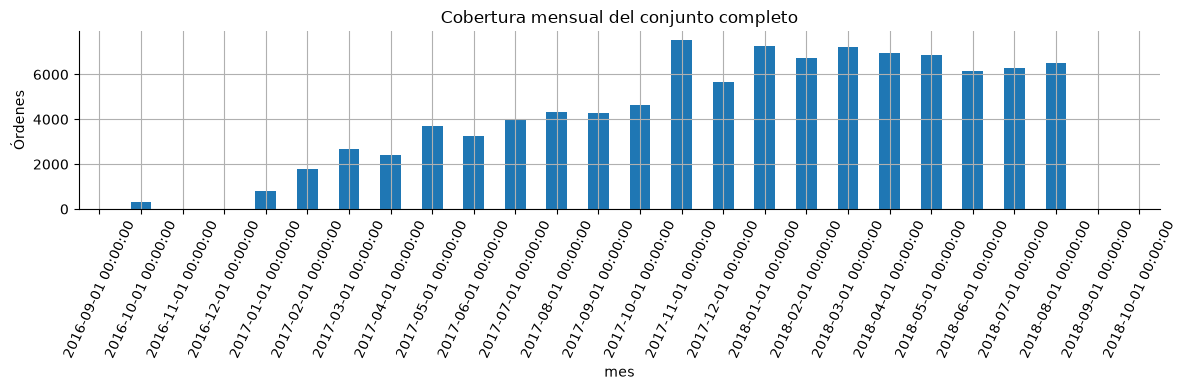

,fecha,ordenes
0,2018-08-01,311
1,2018-08-02,302
2,2018-08-03,314
3,2018-08-04,245
4,2018-08-05,276
...,...,...
41,2018-09-29,1
42,2018-10-01,1
43,2018-10-03,1
44,2018-10-16,1


In [6]:
# El calendario mensual incluye incluso meses sin órdenes.
cobertura=consultar(con,'cobertura.sql'); display(cobertura); exportar(cobertura,'cobertura_mensual')
cobertura.plot.bar(x='mes',y='ordenes',legend=False,title='Cobertura mensual del conjunto completo',rot=65)
plt.ylabel('Órdenes'); figura('cobertura_mensual')
cola=consultar(con,'cola.sql',['2018-08-01']); display(cola); exportar(cola,'cobertura_final')

## 4. Construir una observación por día mediante SQL

La consulta `serie_diaria.sql` genera todas las fechas entre los límites, cuenta compras por día y une ambas tablas. Dentro de este tramo, una fecha sin órdenes se representa con cero.

Completar el calendario es esencial: un rezago de siete filas debe representar siete días. Sin esa regularidad, una media móvil de siete filas podría cubrir más de una semana. Fuera del tramo seleccionado no convertimos automáticamente la ausencia de registros en cero.

,dias,pedidos,minimo,maximo,dias_cero
0,567,97590.0,35,1176,0


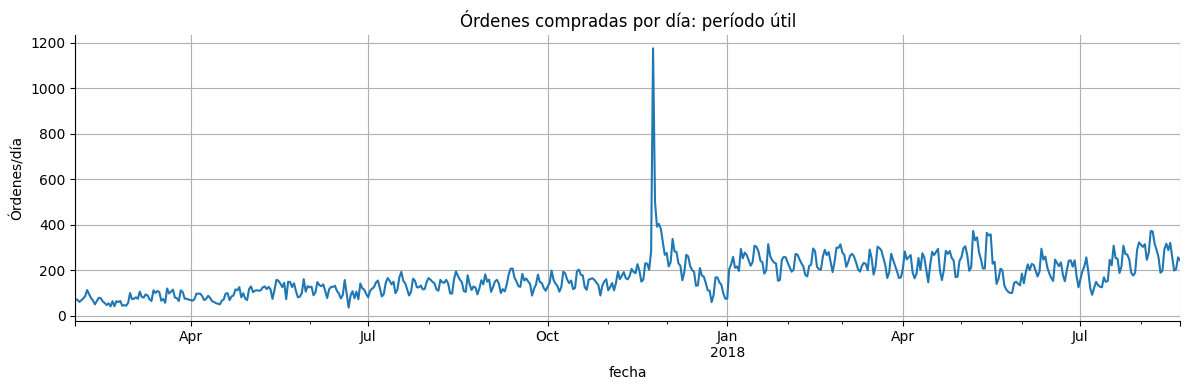

Un pico es una observación que debemos explicar; no se borra automáticamente.


In [5]:
# Las fechas se pasan como parámetros; no se concatenan dentro de la consulta.
serie=consultar(con,'serie_diaria.sql',[INICIO,FIN,INICIO,FIN])
assert serie.fecha.is_unique and serie.y.ge(0).all()
assert serie.fecha.diff().dropna().eq(pd.Timedelta(days=1)).all()
exportar(serie,'serie_diaria'); con.register('serie',serie)
resumen=con.sql('SELECT count(*) dias,sum(y) pedidos,min(y) minimo,max(y) maximo,count(*) FILTER(WHERE y=0) dias_cero FROM serie').df()
display(resumen); exportar(resumen,'resumen_serie')
serie.plot(x='fecha',y='y',legend=False,title='Órdenes compradas por día: período útil')
plt.ylabel('Órdenes/día'); figura('serie_diaria')
print('Un pico es una observación que debemos explicar; no se borra automáticamente.')

## 5. Exploración común: clientes, geografía y entregas

Estas tablas describen el contexto del negocio. Los tiempos de entrega se calculan solo donde existen las fechas necesarias, y los retrasos se miden en días calendario frente a la fecha estimada.

Los compradores recurrentes se cuentan mediante `customer_unique_id`. La concentración geográfica describe dónde se compra, pero no demuestra por sí sola la causa de una variación temporal. Los atributos finales de entrega no entran al modelo de compras futuras.

,observaciones,media_dias_entrega,mediana_dias_entrega,p90_dias_entrega,proporcion_tarde,retraso_medio_dias
0,96470,12.496849,10.0,23.0,0.067731,-11.875889


,poblacion,estado,registros
0,clientes,SP,41746
1,clientes,RJ,12852
2,clientes,MG,11635
3,clientes,RS,5466
4,clientes,PR,5045
...,...,...,...
45,vendedores,AC,1
46,vendedores,PA,1
47,vendedores,MA,1
48,vendedores,PI,1


,compras,clientes
0,1,93099
1,2,2745
2,3,203
3,4,30
4,5,8
5,6,6
6,7,3
7,9,1
8,17,1


,semana,ordenes
0,2016-08-29,1
1,2016-09-05,1
2,2016-09-12,2
3,2016-09-26,1
4,2016-10-03,283
...,...,...
96,2018-09-10,4
97,2018-09-17,2
98,2018-09-24,3
99,2018-10-01,2


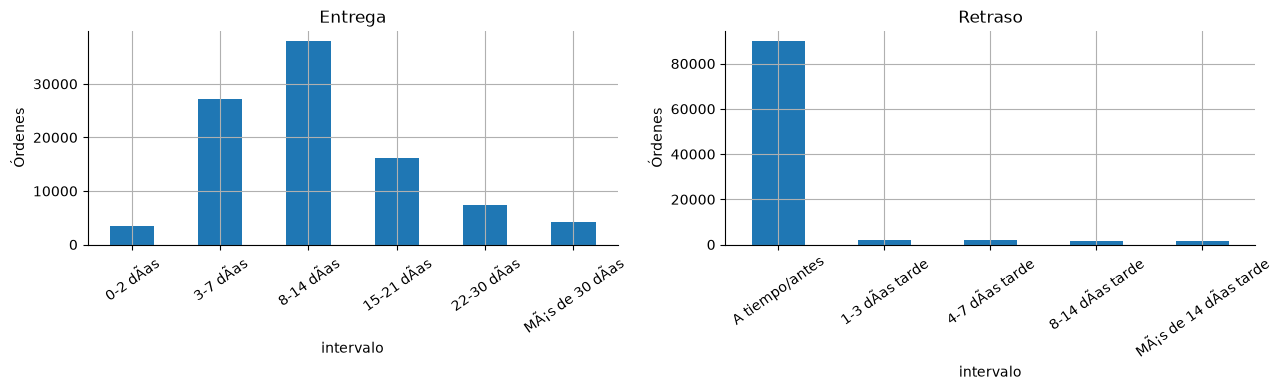

In [7]:
# Lecturas, filtros, uniones y agregaciones de datos crudos permanecen en SQL.
for archivo,nombre in [('eda_entregas.sql','eda_entregas'),('eda_geografia.sql','eda_geografia'),
                      ('eda_clientes.sql','eda_clientes'),('eda_semanal.sql','eda_semanal')]:
    tabla=consultar(con,archivo); display(tabla); exportar(tabla,nombre)
distribuciones=consultar(con,'eda_distribuciones.sql'); exportar(distribuciones,'distribuciones_entrega')
fig,axes=plt.subplots(1,2,figsize=(13,4))
for eje,(tipo,g) in zip(axes,distribuciones.groupby('tipo',sort=False)):
    g.plot.bar(x='intervalo',y='ordenes',ax=eje,legend=False,title=tipo,rot=35)
    eje.set_ylabel('Órdenes')
figura('distribuciones_entrega')
con.close()

## 6. Comprobar que entendimos

**¿Por qué no usamos solamente órdenes entregadas?** Porque su estado final depende de hechos posteriores a la compra y definiría otro objetivo: compras que terminaron entregadas.

**¿Por qué un pago faltante no obliga a borrar una compra?** Porque estamos contando órdenes registradas con fecha válida, no calculando ingresos cobrados.

**¿Qué sale de este notebook?** Una serie diaria regular, una decisión de cobertura explícita y un inventario de calidad. Todavía no hemos elegido un modelo ni atribuido causas a los picos.